In [ ]:
!pip install -q opencv-python


In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import backend as K
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


In [ ]:
!wget -O NuInsSeg.zip https://zenodo.org/records/10518968/files/NuInsSeg.zip


--2026-02-13 06:55:42--  https://zenodo.org/records/10518968/files/NuInsSeg.zip
Resolving zenodo.org (zenodo.org)... 188.184.98.114, 188.184.103.118, 188.185.43.153, ...
Connecting to zenodo.org (zenodo.org)|188.184.98.114|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1627427342 (1.5G) [application/octet-stream]
Saving to: ‘NuInsSeg.zip’

NuInsSeg.zip        100%[===================>]   1.52G  12.5MB/s    in 2m 5s   

2026-02-13 06:57:48 (12.4 MB/s) - ‘NuInsSeg.zip’ saved [1627427342/1627427342]



In [ ]:
!unzip -q NuInsSeg.zip


In [ ]:
IMAGE_DIR = "/content/human bladder/tissue images"
MASK_DIR  = "/content/human bladder/mask binary"

IMG_SIZE = 256
BATCH_SIZE = 2
EPOCHS = 30


In [ ]:
def collect_all_images_and_masks(base_path="/content"):
    image_paths = []
    mask_paths = []

    for folder in os.listdir(base_path):
        folder_path = os.path.join(base_path, folder)
        if not os.path.isdir(folder_path):
            continue

        img_dir = os.path.join(folder_path, "tissue images")
        mask_dir = os.path.join(folder_path, "mask binary")

        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            imgs = sorted([os.path.join(img_dir, f) for f in os.listdir(img_dir)])
            masks = sorted([os.path.join(mask_dir, f) for f in os.listdir(mask_dir)])

            image_paths.extend(imgs)
            mask_paths.extend(masks)

    return image_paths, mask_paths


image_paths, mask_paths = collect_all_images_and_masks("/content")

print("Total Images:", len(image_paths))
print("Total Masks :", len(mask_paths))


Total Images: 665
Total Masks : 665


In [ ]:
train_imgs, val_imgs, train_masks, val_masks = train_test_split(
    image_paths, mask_paths, test_size=0.2, random_state=42
)


In [ ]:
def process_image(img):
    return img / 255.0

def process_mask(mask):
    return (mask > 0).astype("float32")


In [ ]:
class NuInsSegDataset(tf.keras.utils.Sequence):
    def __init__(self, images, masks, batch_size=BATCH_SIZE, **kwargs):
        super().__init__(**kwargs)
        self.images = images
        self.masks = masks
        self.batch_size = batch_size

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))  # FIX

    def __getitem__(self, idx):
        batch_imgs = self.images[idx*self.batch_size:(idx+1)*self.batch_size]
        batch_masks = self.masks[idx*self.batch_size:(idx+1)*self.batch_size]

        imgs, masks = [], []

        for img_p, mask_p in zip(batch_imgs, batch_masks):
            img = cv2.imread(img_p)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            img = process_image(img)

            mask = cv2.imread(mask_p, cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
            mask = process_mask(mask)

            imgs.append(img)
            masks.append(mask[..., np.newaxis])

        return np.array(imgs), np.array(masks)


In [ ]:
train_dataset = NuInsSegDataset(train_imgs, train_masks)
val_dataset   = NuInsSegDataset(val_imgs, val_masks)


In [ ]:
def dice_coef(y_true, y_pred):
    smooth = 1e-6
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        K.sum(y_true_f) + K.sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)


In [ ]:
import tensorflow as tf


def conv_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)

    x = tf.keras.layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    return x


def build_eunet3plus(input_shape=(256, 256, 3)):
    inputs = tf.keras.layers.Input(input_shape)

    # ======================
    # Encoder
    # ======================
    e1 = conv_block(inputs, 64)
    p1 = tf.keras.layers.MaxPooling2D((2, 2))(e1)

    e2 = conv_block(p1, 128)
    p2 = tf.keras.layers.MaxPooling2D((2, 2))(e2)

    e3 = conv_block(p2, 256)
    p3 = tf.keras.layers.MaxPooling2D((2, 2))(e3)

    e4 = conv_block(p3, 512)
    p4 = tf.keras.layers.MaxPooling2D((2, 2))(e4)

    e5 = conv_block(p4, 1024)

    # ======================
    # Decoder (UNet3+ style)
    # ======================
    d4 = tf.keras.layers.UpSampling2D((2, 2))(e5)
    d4 = tf.keras.layers.Concatenate()([d4, e4])
    d4 = conv_block(d4, 512)

    d3 = tf.keras.layers.UpSampling2D((2, 2))(d4)
    d3 = tf.keras.layers.Concatenate()([d3, e3])
    d3 = conv_block(d3, 256)

    d2 = tf.keras.layers.UpSampling2D((2, 2))(d3)
    d2 = tf.keras.layers.Concatenate()([d2, e2])
    d2 = conv_block(d2, 128)

    d1 = tf.keras.layers.UpSampling2D((2, 2))(d2)
    d1 = tf.keras.layers.Concatenate()([d1, e1])
    d1 = conv_block(d1, 64)

    # ======================
    # Output
    # ======================
    outputs = tf.keras.layers.Conv2D(
        1, (1, 1), activation="sigmoid", padding="same"
    )(d1)

    model = tf.keras.models.Model(inputs, outputs, name="eUNet3Plus")
    return model


# Build model
model = build_eunet3plus()


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=dice_loss,
    metrics=[dice_coef, "accuracy"]
)


In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)


Epoch 1/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 97s 187ms/step - accuracy: 0.7472 - dice_coef: 0.4758 - loss: 0.5242 - val_accuracy: 0.8709 - val_dice_coef: 0.4049 - val_loss: 0.5956
Epoch 2/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 44s 166ms/step - accuracy: 0.8939 - dice_coef: 0.6202 - loss: 0.3798 - val_accuracy: 0.9094 - val_dice_coef: 0.6608 - val_loss: 0.3401
Epoch 3/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 45s 168ms/step - accuracy: 0.9021 - dice_coef: 0.6635 - loss: 0.3365 - val_accuracy: 0.8891 - val_dice_coef: 0.6708 - val_loss: 0.3308
Epoch 4/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 45s 169ms/step - accuracy: 0.9198 - dice_coef: 0.7077 - loss: 0.2923 - val_accuracy: 0.8891 - val_dice_coef: 0.6762 - val_loss: 0.3254
Epoch 5/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 45s 168ms/step - accuracy: 0.9290 - dice_coef: 0.7272 - loss: 0.2728 - val_accuracy: 0.9159 - val_dice_coef: 0.7247 - val_loss: 0.2767
Epoch 6/30
266/266 ━━━━━━━━━━━━━━━━━━━━ 45s 168ms/step - accuracy: 0.9318 - dice_coef: 0.7474 - loss: 0.2526 - val_accuracy: 

In [ ]:
def dice_score(y_true, y_pred):
    smooth = 1e-6
    y_true_f = y_true.flatten()
    y_pred_f = y_pred.flatten()
    intersection = np.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (
        np.sum(y_true_f) + np.sum(y_pred_f) + smooth
    )

def iou_score(y_true, y_pred):
    smooth = 1e-6
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)


In [ ]:
def visualize_prediction_nuinsseg(model, img_path, mask_path):
    # Load input image
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img_n = process_image(img)

    # Load ground truth mask
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
    mask = (mask > 0)   # BOOLEAN (IMPORTANT)

    # Prediction
    pred = model.predict(img_n[np.newaxis, ...], verbose=0)[0]
    pred = (pred > 0.5)
    pred = pred.squeeze()   # BOOLEAN

    # 🔒 SAFE metric computation (NO overflow possible)
    intersection = np.logical_and(mask, pred).sum()
    union = np.logical_or(mask, pred).sum()

    iou = intersection / (union + 1e-6)
    dice = (2 * intersection) / (mask.sum() + pred.sum() + 1e-6)

    # Plot (same-to-same style)
    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(mask, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(pred, cmap="gray")
    plt.title(f"Prediction\nIoU={iou:.3f}  Dice={dice:.3f}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


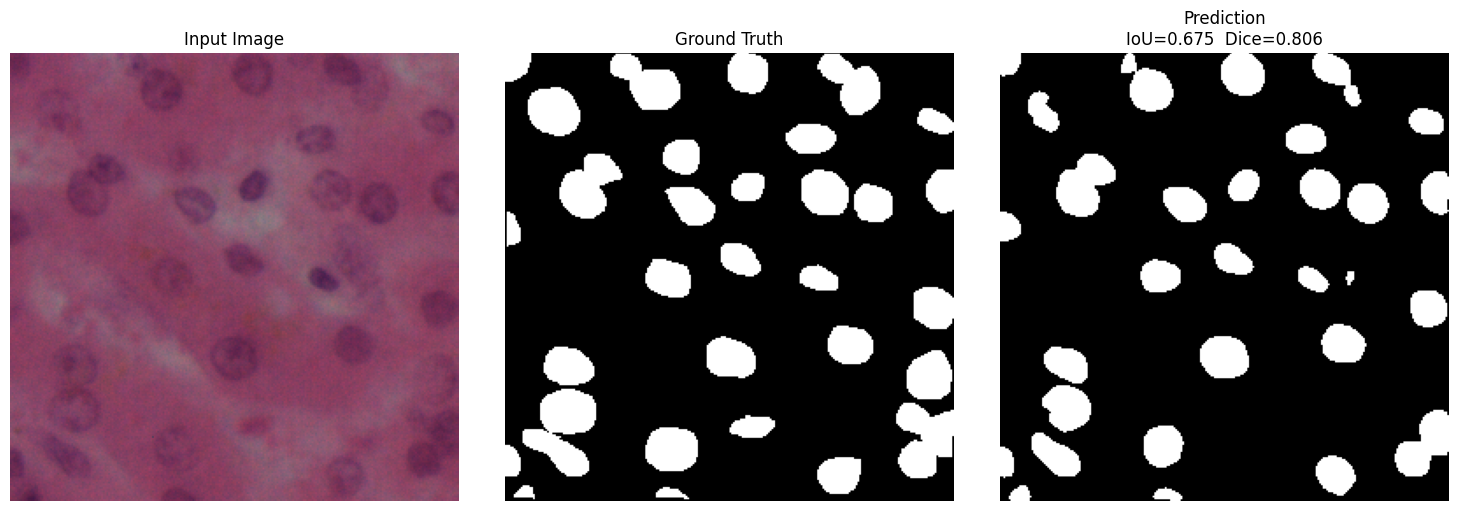

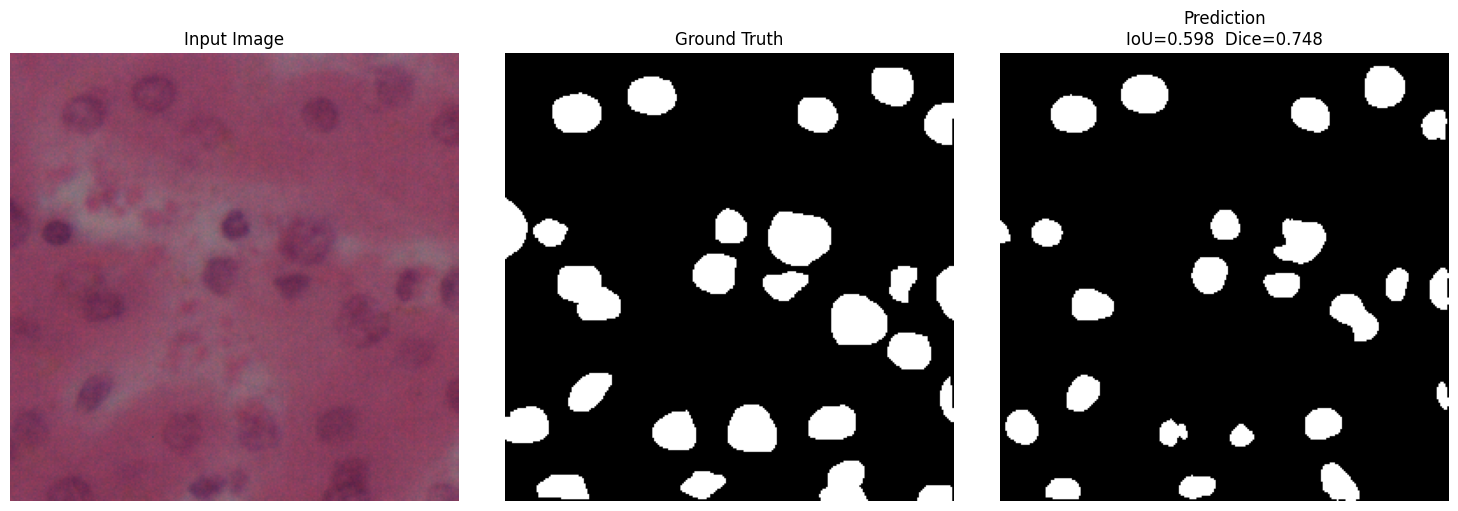

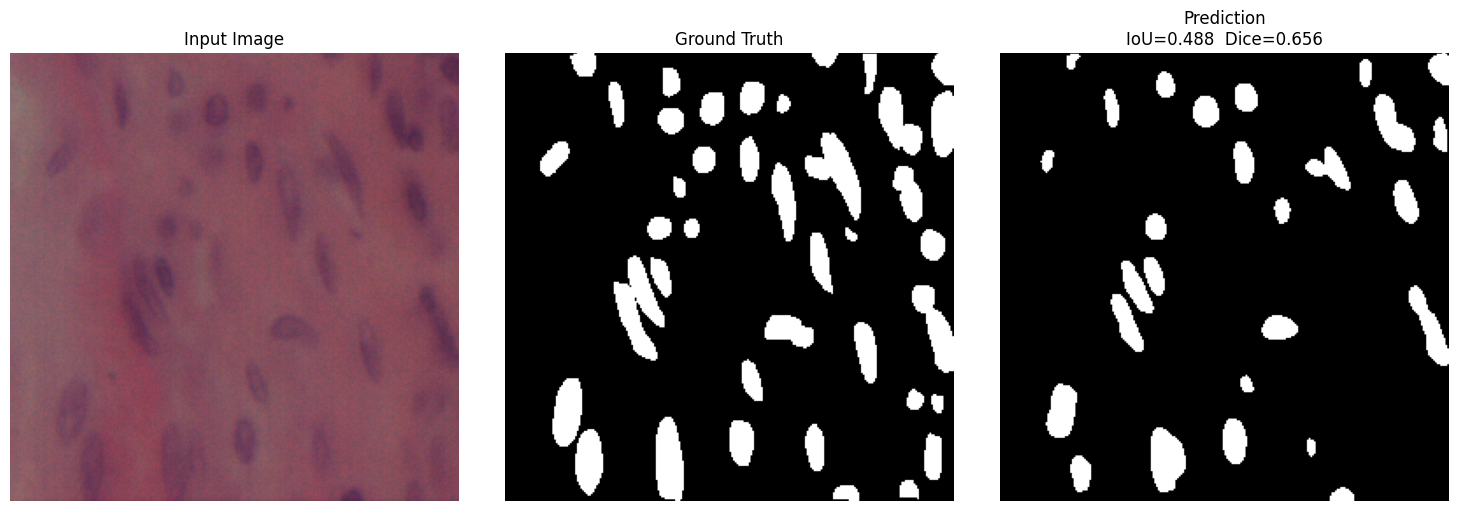

In [ ]:
# Show predictions for 3 validation images
for i in range(3):
    visualize_prediction_nuinsseg(
        model,
        val_imgs[i],
        val_masks[i]
    )
